In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score


In [2]:
df = pd.read_csv('datasets/Mall_Customers.csv')

In [3]:
df

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
...,...,...,...,...,...
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


In [5]:
features = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
X = df[features].copy()

In [6]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [7]:
# This value is only for the diagnostic k-distance plot below.
# Final DBSCAN parameters are selected by the grid search in the next section.
k_distance_min_samples = 5
neighbors = NearestNeighbors(n_neighbors=k_distance_min_samples).fit(X_scaled)
distances, _ = neighbors.kneighbors(X_scaled)
k_distances = sorted(distances[:, -1])


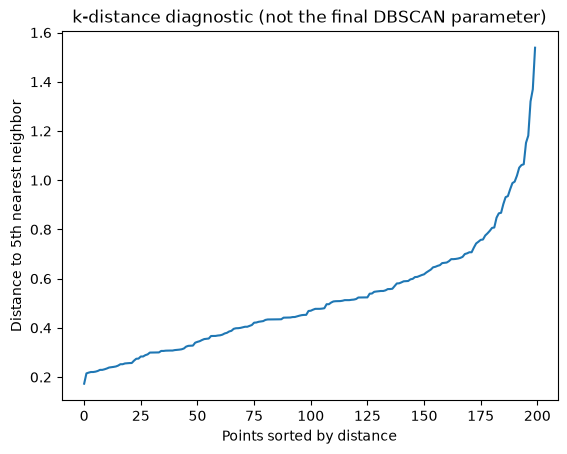

In [8]:
plt.plot(k_distances)
plt.xlabel("Points sorted by distance")
plt.ylabel(f"Distance to {k_distance_min_samples}th nearest neighbor")
plt.title("k-distance diagnostic (not the final DBSCAN parameter)")
plt.show()


In [9]:
# Search eps and min_samples using silhouette score.
# Noise points (-1) are excluded from silhouette calculation, but tracked below.
eps_values = np.arange(0.2, 2.01, 0.05)
min_samples_values = [3, 4, 5, 6, 8, 10]
max_noise_fraction = 0.50

results = []
for min_samples_candidate in min_samples_values:
    for eps_candidate in eps_values:
        labels = DBSCAN(
            eps=float(eps_candidate),
            min_samples=min_samples_candidate
        ).fit_predict(X_scaled)

        cluster_ids = set(labels) - {-1}
        n_clusters_candidate = len(cluster_ids)
        noise_mask = labels == -1
        n_noise_candidate = int(noise_mask.sum())
        noise_fraction_candidate = n_noise_candidate / len(labels)
        clustered_mask = ~noise_mask

        # Silhouette requires at least two clusters and more samples than clusters.
        if (n_clusters_candidate >= 2
                and clustered_mask.sum() > n_clusters_candidate
                and noise_fraction_candidate < max_noise_fraction):
            score = silhouette_score(X_scaled[clustered_mask], labels[clustered_mask])
        else:
            score = np.nan

        results.append({
            'eps': float(eps_candidate),
            'min_samples': min_samples_candidate,
            'n_clusters': n_clusters_candidate,
            'n_noise': n_noise_candidate,
            'noise_fraction': noise_fraction_candidate,
            'silhouette': score
        })

results_df = pd.DataFrame(results)
valid_results = results_df.dropna(subset=['silhouette'])

if valid_results.empty:
    raise ValueError(
        'No parameter combination produced at least two clusters with less '
        'than 50% noise. Expand eps_values or adjust min_samples_values.'
    )

# Select the candidate with the highest silhouette score among valid results.
best = valid_results.loc[valid_results['silhouette'].idxmax()]
best_eps = float(best['eps'])
best_min_samples = int(best['min_samples'])

# These tuned values are used by the final DBSCAN model below.
eps = best_eps
min_samples = best_min_samples

print('Selected DBSCAN parameters (highest valid silhouette score):')
print(f'eps = {eps}, min_samples = {min_samples}')
print(best.to_string())
print('\nTop 10 candidates:')
print(valid_results.sort_values('silhouette', ascending=False).head(10).round(3).to_string(index=False))

# Fit DBSCAN using the selected hyperparameters.
dbscan = DBSCAN(eps=eps, min_samples=min_samples)
df['Cluster'] = dbscan.fit_predict(X_scaled)


Selected DBSCAN parameters (highest valid silhouette score):
eps = 0.44999999999999996, min_samples = 6
eps                0.450000
min_samples        6.000000
n_clusters         6.000000
n_noise           85.000000
noise_fraction     0.425000
silhouette         0.555794

Top 10 candidates:
 eps  min_samples  n_clusters  n_noise  noise_fraction  silhouette
0.45            6           6       85           0.425       0.556
0.45            5           5       75           0.375       0.542
0.55           10           5       84           0.420       0.541
0.60           10           4       66           0.330       0.530
0.50            6           5       66           0.330       0.528
0.40            5           6       98           0.490       0.519
0.55            8           5       62           0.310       0.516
0.50            8           5       92           0.460       0.505
0.35            4           8       97           0.485       0.495
0.45            4           7       57

In [10]:
# DBSCAN labels noise points as -1
n_clusters = len(set(df["Cluster"])) - (1 if -1 in df["Cluster"].values else 0)
n_noise = (df["Cluster"] == -1).sum()
print(f"Clusters found: {n_clusters}")
print(f"Noise points: {n_noise} of {len(df)}")


Clusters found: 6
Noise points: 85 of 200


In [11]:
# Summarize each cluster (excluding noise)
print(
    df[df["Cluster"] != -1]
    .groupby("Cluster")[features]
    .mean()
    .round(1)
)

          Age  Annual Income (k$)  Spending Score (1-100)
Cluster                                                  
0        23.9                20.7                    74.7
1        23.8                54.2                    51.4
2        48.6                53.4                    48.1
3        64.4                54.1                    51.0
4        32.6                80.8                    83.0
5        43.3                80.0                    15.5


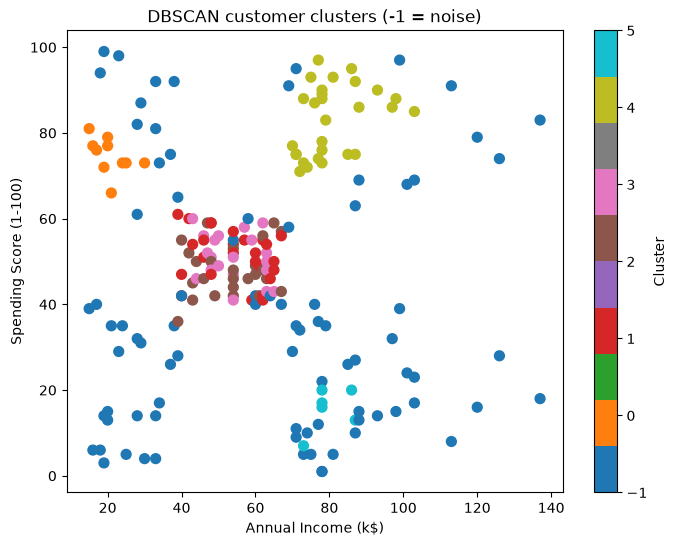

In [12]:
# Plot income vs. spending score, colored by DBSCAN cluster
plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    df["Annual Income (k$)"],
    df["Spending Score (1-100)"],
    c=df["Cluster"],
    cmap="tab10",
    s=50
)
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("DBSCAN customer clusters (-1 = noise)")
plt.colorbar(scatter, label="Cluster")
plt.show()

In [13]:
# Example new customer: age, annual income (k$), spending score
new_customer = pd.DataFrame([[5, 0, 90]], columns=features)
new_customer_scaled = scaler.transform(new_customer)

# DBSCAN has no predict() method, so refit with the new customer included
combined_scaled = np.vstack([X_scaled, new_customer_scaled])
combined_model = DBSCAN(eps=dbscan.eps, min_samples=dbscan.min_samples)
combined_labels = combined_model.fit_predict(combined_scaled)
new_label = combined_labels[-1]
print(new_label)
# print("New customer:", dict(zip(features, new_customer.iloc[0])))
# if new_label == -1:
#     print("Analysis: this customer is noise (not in a dense cluster).")
# else:
#     print(f"Analysis: this customer belongs to cluster {new_label}.")

-1
